# Predicción de series temporales con PyTorch
### Jena Climate: ¿qué temperatura hará dentro de 24 horas?

**Objetivo:** dado lo que ha pasado en los últimos **5 días** (presión, humedad, viento, temperatura...), predecir la **temperatura exactamente 24 horas después** del último dato.

Vamos a construir, comparar y entender estos modelos:

| # | Modelo | Qué aprendemos |
|---|--------|----------------|
| 0 | Baseline "mañana = hoy" | Sin baseline no sabes si tu red sirve para algo |
| 1 | Densa (MLP) | Una red que ignora el orden temporal |
| 2 | 1D-CNN | Detectar patrones locales en el tiempo |
| 3 | LSTM | Memoria: leer la secuencia paso a paso |
| 4 | GRU apilada | Una variante más ligera y más profunda |

**Dataset:** 8 años de mediciones meteorológicas en Jena (Alemania), una cada 10 minutos, 14 variables.

> 💡 **Cómo usar este notebook para aprender:** antes de ejecutar cada modelo, apunta qué MAE (en °C) crees que va a sacar. Aprenderás mucho de los fallos de tu intuición.

> ⚙️ Pensado para **Google Colab con GPU** (Entorno de ejecución → Cambiar tipo → GPU). En CPU funciona, pero LSTM/GRU tardarán más.

## ¿Por qué las series temporales son distintas a lo que ya has hecho?

En MNIST, Titanic, perros vs gatos o IMDB, cada ejemplo era independiente y podías mezclarlos al azar. Aquí **no**:

1. **El orden importa.** Los datos de hoy dependen de los de ayer.
2. **El split es cronológico.** Entrenamos con el pasado y evaluamos con el futuro. Si mezclas al azar, el modelo "ve" días vecinos del que evalúa y los resultados son demasiado optimistas (*data leakage*).
3. **Normalizar solo con estadísticas del train.** Usar la media de todo el dataset sería "mirar al futuro".
4. **Baseline obligatorio.** En series temporales, el truco de "repetir el último valor" suele ser sorprendentemente difícil de batir.

In [1]:
import os, copy, time, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| dispositivo:", device)

PyTorch: 2.14.1+cu132 | dispositivo: cuda


## 1. Cargar y explorar los datos

In [2]:
URLS = [
    "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip",
    "https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip",
]
ZIP = "jena_climate_2009_2016.csv.zip"
CSV = "jena_climate_2009_2016.csv"

if not os.path.exists(CSV):
    for url in URLS:
        try:
            urllib.request.urlretrieve(url, ZIP)
            with zipfile.ZipFile(ZIP) as z:
                z.extractall(".")
            print("Descargado desde:", url)
            break
        except Exception as e:
            print("Falló", url, "->", e)
    else:
        raise FileNotFoundError("No se pudo descargar; bájalo a mano y deja el CSV junto al notebook.")

df = pd.read_csv(CSV)
print(df.shape)
df.head()

(420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [3]:
# Convertimos la columna de fecha a datetime (formato alemán: día.mes.año)
date_time = pd.to_datetime(df.pop("Date Time"), format="%d.%m.%Y %H:%M:%S") # Series de pandas con las fechas por separado

print("Desde:", date_time.iloc[0], " Hasta:", date_time.iloc[-1])
print("Filas:", len(df), "(una cada 10 min)")
df.describe().T

Desde: 2009-01-01 00:10:00  Hasta: 2017-01-01 00:00:00
Filas: 420551 (una cada 10 min)


,count,mean,std,min,25%,50%,75%,max
p (mbar),420551.0,989.212776,8.358481,913.60,984.20,989.58,994.72,1015.35
T (degC),420551.0,9.450147,8.423365,-23.01,3.36,9.42,15.47,37.28
Tpot (K),420551.0,283.492743,8.504471,250.60,277.43,283.47,289.53,311.34
Tdew (degC),420551.0,4.955854,6.730674,-25.01,0.24,5.22,10.07,23.11
rh (%),420551.0,76.008259,16.476175,12.95,65.21,79.30,89.40,100.00
VPmax (mbar),420551.0,13.576251,7.739020,0.95,7.78,11.82,17.60,63.77
VPact (mbar),420551.0,9.533756,4.184164,0.79,6.21,8.86,12.35,28.32
VPdef (mbar),420551.0,4.042412,4.896851,0.00,0.87,2.19,5.30,46.01
sh (g/kg),420551.0,6.022408,2.656139,0.50,3.92,5.59,7.80,18.13
H2OC (mmol/mol),420551.0,9.640223,4.235395,0.80,6.29,8.96,12.49,28.82


### Limpieza: ¡hay un error en los datos!
Mira `wv (m/s)` y `max. wv (m/s)` (velocidad del viento) en el `describe()` anterior: el mínimo es **-9999**. Una velocidad de viento negativa no existe: es un código de "dato erróneo". Lo pondremos a 0.

In [4]:
print("Errores en wv:", (df["wv (m/s)"] == -9999.0).sum(),
      "| en max. wv:", (df["max. wv (m/s)"] == -9999.0).sum())

df["wv (m/s)"] = df["wv (m/s)"].replace(-9999.0, 0.0)
df["max. wv (m/s)"] = df["max. wv (m/s)"].replace(-9999.0, 0.0)
print("Mínimo wv tras limpiar:", df["wv (m/s)"].min())

Errores en wv: 18 | en max. wv: 20
Mínimo wv tras limpiar: 0.0


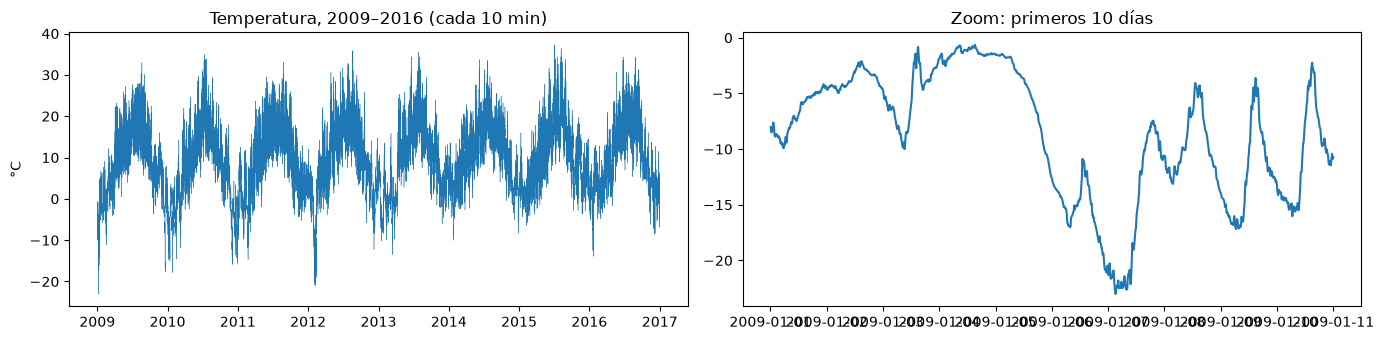

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(date_time, df["T (degC)"], lw=0.3)
axes[0].set_title("Temperatura, 2009–2016 (cada 10 min)")
axes[0].set_ylabel("°C")

# Zoom: 10 días = 1440 mediciones
axes[1].plot(date_time[:1440], df["T (degC)"][:1440])
axes[1].set_title("Zoom: primeros 10 días")
plt.tight_layout(); plt.show()

🤔 **Pregunta:** ¿qué dos periodicidades ves?

<details><summary>Respuesta</summary>

Estacionalidad **anual** (verano caliente / invierno frío) y **diaria** (más calor por la tarde, más frío de madrugada). Las redes tendrán que aprender ambas.
</details>

## 2. Preparar las variables (feature engineering)

Tres ajustes sencillos que ayudan mucho:

1. **Submuestrear a 1 dato por hora.** Predecir a 24 h vista no necesita resolución de 10 min, y así las secuencias son 6 veces más cortas (las redes recurrentes entrenan mucho mejor con secuencias cortas).
2. **Viento como vector.** `wd (deg)` es un ángulo: 359° y 1° están pegados, pero numéricamente están lejísimos. Lo convertimos en componentes (x, y).
3. **Hora del día y época del año como seno/coseno.** Así la red sabe "qué hora es" y "qué estación es" de forma continua (las 23:59 están cerca de las 00:00).

In [6]:
# 1) Submuestreo: nos quedamos con 1 de cada 6 filas (una por hora)
df = df.iloc[5::6].reset_index(drop=True)
date_time = date_time.iloc[5::6].reset_index(drop=True)

# 2) Viento -> vector (x, y)
wd_rad = df.pop("wd (deg)") * np.pi / 180
wv, max_wv = df.pop("wv (m/s)"), df.pop("max. wv (m/s)")
df["Wx"], df["Wy"] = wv * np.cos(wd_rad), wv * np.sin(wd_rad)
df["max Wx"], df["max Wy"] = max_wv * np.cos(wd_rad), max_wv * np.sin(wd_rad)

# 3) Tiempo cíclico
segundos = date_time.map(pd.Timestamp.timestamp)
DIA, ANIO = 24 * 3600, 365.2425 * 24 * 3600
df["Day sin"],  df["Day cos"]  = np.sin(segundos * 2 * np.pi / DIA),  np.cos(segundos * 2 * np.pi / DIA) # En que parte del dia estamos
df["Year sin"], df["Year cos"] = np.sin(segundos * 2 * np.pi / ANIO), np.cos(segundos * 2 * np.pi / ANIO) # En que estacion estamos

print(df.shape)
print(list(df.columns))

(70091, 19)
['p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'Wx', 'Wy', 'max Wx', 'max Wy', 'Day sin', 'Day cos', 'Year sin', 'Year cos']


Convierte cada fecha en segundos transcurridos desde el 1 de enero de 1970 (el llamado Unix timestamp), para tener un número con el que se pueda calcular.

Por partes:

* date_time es una columna de fechas (por ejemplo 2009-01-01 01:00:00), y el seno y el coseno no se pueden calcular sobre una fecha, solo sobre números.
* .map(f) aplica la función f a cada elemento de la columna. Cada elemento es un pd.Timestamp.
* pd.Timestamp.timestamp es el método que devuelve los segundos desde 1970 de un Timestamp. Se pasa sin paréntesis porque no lo llamas tú, sino que lo llama .map una vez por fila.

Ejemplo:

2009-01-01 00:00:00  →  1230768000.0
2009-01-01 01:00:00  →  1230771600.0   (3600 segundos más)

Para qué lo usamos: en las líneas siguientes se calcula

np.sin(segundos * 2 * np.pi / DIA)

Con DIA = 24*3600 segundos, el ángulo segundos * 2π / DIA da una vuelta completa cada 24 horas, así que seno y coseno representan “en qué punto del día estamos”. Con ANIO se hace lo mismo para la estación del año.

Como las fechas no tienen zona horaria, pandas las trata como UTC. Eso solo desplaza la fase del ciclo, y a la red le da igual porque lo único que necesita es la periodicidad.

## 3. Split cronológico y normalización

```
|-------- 50% train --------|---- 25% val ----|---- 25% test ----|
2009                                                          2016
```
La media y la desviación típica se calculan **solo con el train**.

Normalizamos **también el objetivo** (la temperatura). En PyTorch es lo habitual: una red que tiene que producir "14.3" arranca mucho peor que una que produce valores cercanos a 0. Después, para reportar, multiplicaremos el error por la desviación típica y lo tendremos en °C.

In [7]:
n = len(df)
n_train, n_val = int(0.5 * n), int(0.25 * n)
n_test = n - n_train - n_val
print(f"train={n_train}  val={n_val}  test={n_test}")

mean = df.iloc[:n_train].mean()
std  = df.iloc[:n_train].std()

data = torch.tensor(((df - mean) / std).values, dtype=torch.float32)   # (n, n_features), normalizado

TEMP_IDX   = list(df.columns).index("T (degC)") # Posicion de la columna de temperaturas
temp_mean  = float(mean["T (degC)"])
temp_std   = float(std["T (degC)"])
n_features = data.shape[1]

target = data[:, TEMP_IDX]            # temperatura NORMALIZADA (es el objetivo)
print("Nº de variables de entrada:", n_features)

train=35045  val=17522  test=17524
Nº de variables de entrada: 19


## 4. Crear las ventanas: un `Dataset` propio

Cada ejemplo de entrenamiento es una **ventana deslizante**:

```
entrada:  120 horas consecutivas (5 días) x n_features
objetivo: temperatura 24 horas después de la última hora de la ventana

 índice:   i ........................ i+119 | ... | i+143
           [------ ventana (120 h) ------]  24 h   ↑ target = i + DELAY
```

Para eso heredamos de `torch.utils.data.Dataset` e implementamos dos métodos: `__len__` (cuántos ejemplos hay) y `__getitem__` (dame el ejemplo número *k*). No duplicamos datos: cada ventana es un *corte* (slice) del tensor grande.

**Detalle importante:** exigimos que **tanto la ventana como su target** caigan dentro del mismo tramo. Así ninguna ventana de train tiene su objetivo en el periodo de validación (esa filtración sutil es fácil de cometer).

In [8]:
SEQ_LEN   = 120                      # 5 días de historia (horas)
HORIZONTE = 24                       # predecimos 24 h después
DELAY     = SEQ_LEN + HORIZONTE - 1  # el target del ejemplo i está en i + DELAY
BATCH     = 256

class VentanasDataset(Dataset):
    def __init__(self, data, target, start, end):
        self.data, self.target = data, target
        self.start = start
        self.n = end - start - DELAY          # nº de ventanas cuyo target también cae antes de `end`

    def __len__(self):
        return self.n

    def __getitem__(self, k):
        i = self.start + k
        x = self.data[i : i + SEQ_LEN]        # (SEQ_LEN, n_features)
        y = self.target[i + DELAY]            # escalar
        return x, y

train_ds = VentanasDataset(data, target, 0, n_train)
val_ds   = VentanasDataset(data, target, n_train, n_train + n_val)
test_ds  = VentanasDataset(data, target, n_train + n_val, n)

# shuffle solo en train: mezcla el ORDEN DE LAS VENTANAS; dentro de cada ventana el orden temporal se respeta
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False)
test_dl  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False)

print("Ventanas -> train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))
x, y = next(iter(train_dl))
print("Entradas:", tuple(x.shape), "(batch, tiempo, variables)")
print("Objetivos:", tuple(y.shape))

Ventanas -> train: 34902 | val: 17379 | test: 17381
Entradas: (256, 120, 19) (batch, tiempo, variables)
Objetivos: (256,)


🔎 **Comprobación importante:** verificamos a mano que la alineación es correcta. Si el target estuviera desfasado, el modelo "aprendería" algo falso y no nos daríamos cuenta.

In [9]:
x0, y0 = val_ds[0]
i = n_train
print("¿Ventana correcta?", torch.equal(x0, data[i : i + SEQ_LEN]))
print("¿Target correcto? ", torch.isclose(y0, target[i + DELAY]).item())
print("Hora de fin de ventana:", date_time[i + SEQ_LEN - 1])
print("Hora del target:       ", date_time[i + DELAY])

¿Ventana correcta? True
¿Target correcto?  True
Hora de fin de ventana: 2013-01-04 05:20:00
Hora del target:        2013-01-05 05:20:00


## 5. Baseline: "dentro de 24 h hará la misma temperatura que ahora"

Como el ciclo diario es muy fuerte, la temperatura de hoy a esta hora se parece a la de mañana a esta hora. Este "modelo" no tiene parámetros ni entrenamiento. **Cualquier red que no lo supere es inútil.**

Métrica: **MAE** (error absoluto medio) en °C.

In [10]:
def mae_baseline(dl):
    total, count = 0.0, 0
    for x, y in dl:
        pred = x[:, -1, TEMP_IDX]                 # temperatura de la ÚLTIMA hora de la ventana
        total += (pred - y).abs().sum().item()
        count += len(y)
    return total / count * temp_std               # normalizado -> °C

resultados, historiales, modelos = {}, {}, {}
resultados["0. Baseline"] = {"val_mae": mae_baseline(val_dl), "test_mae": mae_baseline(test_dl), "params": 0}
print(f"Baseline  →  val MAE: {resultados['0. Baseline']['val_mae']:.2f} °C   |   test MAE: {resultados['0. Baseline']['test_mae']:.2f} °C")

Baseline  →  val MAE: 2.44 °C   |   test MAE: 2.62 °C


## 6. El bucle de entrenamiento (escrito a mano)

Aquí no hay `model.fit()`. Los cinco pasos de cada batch son siempre los mismos:

```python
pred = model(x)              # 1. forward
loss = loss_fn(pred, y)      # 2. calcular el error
opt.zero_grad()              # 3. borrar gradientes anteriores
loss.backward()              # 4. backprop: calcular gradientes
opt.step()                   # 5. actualizar pesos
```

Además:
- `model.train()` / `model.eval()` activan/desactivan Dropout.
- `torch.no_grad()` en validación: no necesitamos gradientes, ahorra memoria y tiempo.
- **Early stopping:** si la validación no mejora en `patience` épocas, paramos y nos quedamos con los mejores pesos (guardados con `deepcopy` del `state_dict`).

In [11]:
@torch.no_grad()
def evaluar(model, dl):
    # Devuelve el MAE en °C
    model.eval()
    total, count = 0.0, 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        total += (model(x) - y).abs().sum().item()
        count += len(y)
    return total / count * temp_std

def entrenar(nombre, model, epochs=30, lr=1e-3, patience=4):
    model = model.to(device)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    hist = {"train_mae": [], "val_mae": []}
    mejor_val, mejor_estado, sin_mejora = float("inf"), None, 0
    print(f"{nombre} ({n_params:,} parámetros)")

    for epoca in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        err_abs, count = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            pred = model(x)                    # 1. forward
            loss = loss_fn(pred, y)            # 2. error
            opt.zero_grad()                    # 3. limpiar gradientes
            loss.backward()                    # 4. backprop
            opt.step()                         # 5. actualizar pesos
            err_abs += (pred.detach() - y).abs().sum().item(); count += len(y)

        train_mae = err_abs / count * temp_std
        val_mae = evaluar(model, val_dl)
        hist["train_mae"].append(train_mae); hist["val_mae"].append(val_mae)
        print(f"  época {epoca:2d} | train MAE {train_mae:.3f} °C | val MAE {val_mae:.3f} °C | {time.time()-t0:.0f}s")

        if val_mae < mejor_val:
            mejor_val, mejor_estado, sin_mejora = val_mae, copy.deepcopy(model.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= patience:
                print("  → early stopping"); break

    model.load_state_dict(mejor_estado)          # volvemos a los mejores pesos
    test_mae = evaluar(model, test_dl)
    resultados[nombre] = {"val_mae": mejor_val, "test_mae": test_mae, "params": n_params}
    historiales[nombre], modelos[nombre] = hist, model
    print(f"  ✔ val MAE: {mejor_val:.2f} °C | test MAE: {test_mae:.2f} °C\n")

## 7. Modelo 1: Red densa (MLP)

Aplanamos las 120 horas × `n_features` variables en un vector largo y lo metemos en una red densa. Es el "modelo ingenuo": **no sabe que los datos tienen orden temporal**; para él, la hora 3 y la hora 117 son simplemente columnas distintas.

🤔 *¿Superará al baseline?*

In [12]:
class Densa(nn.Module):
    def __init__(self, seq_len, n_features, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                                  # (B, T, F) -> (B, T*F)
            nn.Linear(seq_len * n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)                     # (B, 1) -> (B,)

entrenar("1. Densa", Densa(SEQ_LEN, n_features))

1. Densa (73,025 parámetros)
  época  1 | train MAE 2.839 °C | val MAE 2.496 °C | 1s
  época  2 | train MAE 2.304 °C | val MAE 2.554 °C | 1s
  época  3 | train MAE 2.234 °C | val MAE 2.549 °C | 1s
  época  4 | train MAE 2.102 °C | val MAE 2.496 °C | 1s
  época  5 | train MAE 2.038 °C | val MAE 2.544 °C | 1s
  época  6 | train MAE 1.983 °C | val MAE 2.572 °C | 1s
  época  7 | train MAE 1.933 °C | val MAE 2.552 °C | 1s
  época  8 | train MAE 1.889 °C | val MAE 2.599 °C | 1s
  → early stopping
  ✔ val MAE: 2.50 °C | test MAE: 2.62 °C



## 8. Modelo 2: 1D-CNN

Una `Conv1d` desliza un filtro **a lo largo del eje temporal**, igual que una `Conv2d` lo desliza por una imagen. Detecta patrones locales ("subida brusca de presión en 6 horas").

⚠️ **Trampa típica de PyTorch:** `Conv1d` espera `(batch, canales, tiempo)`, pero nuestros datos son `(batch, tiempo, variables)`. Hay que hacer `x.transpose(1, 2)`: las *variables* hacen de *canales*. (Las `LSTM` con `batch_first=True` sí aceptan `(batch, tiempo, variables)` directamente.)

- `Conv1d(n_features, 8, 24)`: 8 filtros que miran ventanas de 24 horas (¡un día entero!).
- `MaxPool1d(2)`: reduce la longitud temporal a la mitad.
- `AdaptiveAvgPool1d(1)`: promedia todo el eje temporal → **aquí se pierde el orden global**.

🤔 *Piensa:* ¿por qué ese último paso puede ser un problema para predecir temperatura?

In [13]:
class CNN1D(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_features, 8, kernel_size=24), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(8, 8, kernel_size=12),          nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(8, 8, kernel_size=6),           nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),                  # (B, 8, L) -> (B, 8, 1)
        )
        self.fc = nn.Linear(8, 1)

    def forward(self, x):
        x = x.transpose(1, 2)                         # (B, T, F) -> (B, F, T)
        x = self.conv(x).squeeze(-1)                  # (B, 8)
        return self.fc(x).squeeze(-1)

entrenar("2. 1D-CNN", CNN1D(n_features))

2. 1D-CNN (4,833 parámetros)
  época  1 | train MAE 4.036 °C | val MAE 3.389 °C | 8s
  época  2 | train MAE 3.145 °C | val MAE 2.814 °C | 12s
  época  3 | train MAE 2.818 °C | val MAE 2.710 °C | 5s
  época  4 | train MAE 2.750 °C | val MAE 2.707 °C | 3s
  época  5 | train MAE 2.721 °C | val MAE 2.678 °C | 3s
  época  6 | train MAE 2.686 °C | val MAE 2.886 °C | 3s
  época  7 | train MAE 2.657 °C | val MAE 2.694 °C | 3s
  época  8 | train MAE 2.626 °C | val MAE 2.693 °C | 3s
  época  9 | train MAE 2.606 °C | val MAE 2.655 °C | 3s
  época 10 | train MAE 2.601 °C | val MAE 2.688 °C | 3s
  época 11 | train MAE 2.572 °C | val MAE 2.734 °C | 3s
  época 12 | train MAE 2.550 °C | val MAE 2.777 °C | 3s
  época 13 | train MAE 2.531 °C | val MAE 2.799 °C | 3s
  → early stopping
  ✔ val MAE: 2.66 °C | test MAE: 2.80 °C



> 📝 **Lección:** las convoluciones asumen *invarianza a la traslación*: un patrón vale lo mismo esté donde esté. En imágenes ("un gato es un gato en cualquier esquina") eso es genial. En series temporales **la posición sí importa** (el dato de hace 1 hora es mucho más relevante que el de hace 5 días), así que la CNN con pooling global suele quedarse corta aquí.

## 9. Modelo 3: LSTM

Una **LSTM** lee la secuencia **paso a paso** (hora 0, hora 1, ... hora 119) manteniendo una *memoria interna*. En cada paso decide con unas "puertas" (gates):

- 🚪 **forget gate:** ¿qué olvido de la memoria?
- 🚪 **input gate:** ¿qué información nueva guardo?
- 🚪 **output gate:** ¿qué parte de la memoria expongo?

`nn.LSTM` devuelve `output, (h_n, c_n)`:
- `output`: el estado oculto de **cada** paso, forma `(B, T, hidden)`.
- `h_n`: el estado oculto **final** de cada capa, forma `(num_layers, B, hidden)`.
- `c_n`: la memoria de celda final (la "memoria larga").

Como solo queremos un resumen de toda la secuencia, usamos `h_n[-1]` (estado final de la última capa) y una `Linear(hidden, 1)` lo convierte en temperatura.

In [14]:
class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden=16):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)       # h_n: (1, B, hidden)
        return self.fc(h_n[-1]).squeeze(-1)

entrenar("3. LSTM", LSTMModel(n_features))

3. LSTM (2,385 parámetros)
  época  1 | train MAE 3.881 °C | val MAE 2.383 °C | 1s
  época  2 | train MAE 2.449 °C | val MAE 2.288 °C | 1s
  época  3 | train MAE 2.360 °C | val MAE 2.281 °C | 1s
  época  4 | train MAE 2.320 °C | val MAE 2.274 °C | 1s
  época  5 | train MAE 2.294 °C | val MAE 2.267 °C | 1s
  época  6 | train MAE 2.274 °C | val MAE 2.253 °C | 1s
  época  7 | train MAE 2.262 °C | val MAE 2.280 °C | 1s
  época  8 | train MAE 2.249 °C | val MAE 2.254 °C | 1s
  época  9 | train MAE 2.235 °C | val MAE 2.275 °C | 1s
  época 10 | train MAE 2.226 °C | val MAE 2.270 °C | 1s
  → early stopping
  ✔ val MAE: 2.25 °C | test MAE: 2.32 °C



🧮 **Ejercicio mental:** ¿cuántos parámetros tiene `nn.LSTM(F, H)`? Hay 4 bloques (3 puertas + la celda candidata), cada uno con pesos de entrada (`H×F`), pesos recurrentes (`H×H`) y **dos** vectores de bias (PyTorch usa `b_ih` y `b_hh`; Keras usa solo uno).

Comprueba tu fórmula:

In [15]:
F, H = n_features, 16
formula = 4 * (H * F + H * H + 2 * H)
real = sum(p.numel() for p in modelos["3. LSTM"].lstm.parameters())
print(f"Fórmula: {formula} | Real: {real}")
for nombre, p in modelos["3. LSTM"].lstm.named_parameters():
    print(f"  {nombre:12s} {tuple(p.shape)}")

Fórmula: 2368 | Real: 2368
  weight_ih_l0 (64, 19)
  weight_hh_l0 (64, 16)
  bias_ih_l0   (64,)
  bias_hh_l0   (64,)


## 10. Modelo 4: GRU apilada con Dropout

La **GRU** es una LSTM simplificada (2 puertas en vez de 3, sin celda separada), con menos parámetros y rendimiento parecido.

- `num_layers=2` apila dos GRU: la segunda lee la secuencia de estados ocultos de la primera. PyTorch se encarga del `return_sequences` interno.
- `dropout=0.3` entre capas, más un `Dropout` antes de la salida, para regularizar.

In [16]:
class GRUModel(nn.Module):
    def __init__(self, n_features, hidden=32, layers=2, dropout=0.3):
        super().__init__()
        self.gru = nn.GRU(n_features, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, h_n = self.gru(x)               # h_n: (layers, B, hidden)
        return self.fc(self.drop(h_n[-1])).squeeze(-1)

entrenar("4. GRU x2", GRUModel(n_features))

4. GRU x2 (11,457 parámetros)
  época  1 | train MAE 3.185 °C | val MAE 2.352 °C | 1s
  época  2 | train MAE 2.631 °C | val MAE 2.278 °C | 1s
  época  3 | train MAE 2.546 °C | val MAE 2.281 °C | 1s
  época  4 | train MAE 2.503 °C | val MAE 2.288 °C | 1s
  época  5 | train MAE 2.473 °C | val MAE 2.258 °C | 1s
  época  6 | train MAE 2.462 °C | val MAE 2.265 °C | 1s
  época  7 | train MAE 2.443 °C | val MAE 2.335 °C | 1s
  época  8 | train MAE 2.428 °C | val MAE 2.265 °C | 1s
  época  9 | train MAE 2.401 °C | val MAE 2.276 °C | 1s
  → early stopping
  ✔ val MAE: 2.26 °C | test MAE: 2.31 °C



## 11. Comparación de resultados

In [17]:
tabla = pd.DataFrame(resultados).T.sort_values("val_mae")
tabla["params"] = tabla["params"].astype(int)
tabla[["val_mae", "test_mae"]] = tabla[["val_mae", "test_mae"]].round(3)
tabla

,val_mae,test_mae,params
3. LSTM,2.253,2.324,2385
4. GRU x2,2.258,2.313,11457
0. Baseline,2.441,2.619,0
1. Densa,2.496,2.618,73025
2. 1D-CNN,2.655,2.799,4833


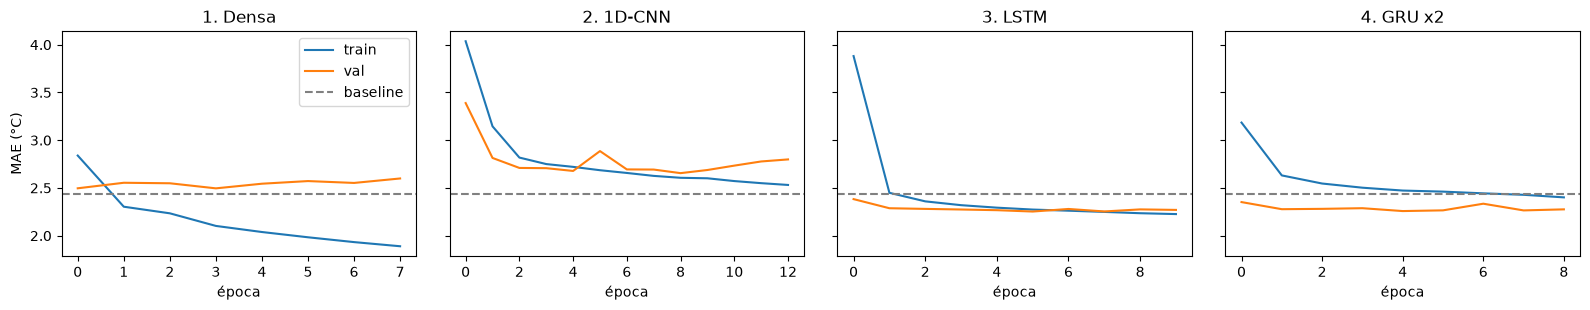

In [18]:
fig, axes = plt.subplots(1, len(historiales), figsize=(4 * len(historiales), 3.2), sharey=True)
for ax, (nombre, h) in zip(axes, historiales.items()):
    ax.plot(h["train_mae"], label="train")
    ax.plot(h["val_mae"], label="val")
    ax.axhline(resultados["0. Baseline"]["val_mae"], color="gray", ls="--", label="baseline")
    ax.set_title(nombre); ax.set_xlabel("época")
axes[0].set_ylabel("MAE (°C)"); axes[0].legend()
plt.tight_layout(); plt.show()

📖 **Cómo leer las curvas**
- *train* baja pero *val* sube → **overfitting**.
- Ambas planas y altas → **underfitting** (modelo demasiado simple o poco entrenado).
- La línea gris es el baseline: lo que quede por encima de ella es un modelo que no aporta nada.
- Ojo: el MAE de *train* se calcula con Dropout activo (`model.train()`), por eso en la GRU puede salir peor que el de val.

*Orientativo:* con este problema, el baseline suele rondar los 2.4–2.6 °C, la densa y la CNN tienen dificultades para superarlo y los modelos recurrentes lo mejoran de forma moderada. Tus números pueden diferir.

## 12. Ver las predicciones del mejor modelo

Mejor modelo según validación: 3. LSTM


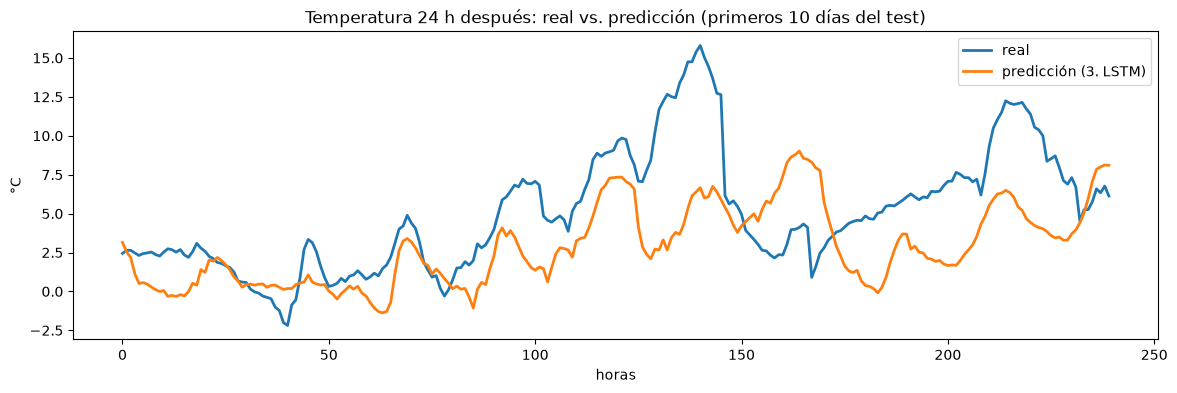

MAE test: 2.32 °C | error máx.: 11.4 °C


In [19]:
mejor = min((k for k in modelos), key=lambda k: resultados[k]["val_mae"])
print("Mejor modelo según validación:", mejor)

@torch.no_grad()
def predecir(model, dl):
    model.eval()
    preds, reales = [], []
    for x, y in dl:
        preds.append(model(x.to(device)).cpu()); reales.append(y)
    # des-normalizamos a °C
    return (torch.cat(preds).numpy() * temp_std + temp_mean,
            torch.cat(reales).numpy() * temp_std + temp_mean)

preds, reales = predecir(modelos[mejor], test_dl)     # test_dl no está barajado → orden cronológico

horas = 24 * 10   # 10 días
plt.figure(figsize=(14, 4))
plt.plot(reales[:horas], label="real", lw=2)
plt.plot(preds[:horas], label=f"predicción ({mejor})", lw=2)
plt.title("Temperatura 24 h después: real vs. predicción (primeros 10 días del test)")
plt.xlabel("horas"); plt.ylabel("°C"); plt.legend(); plt.show()

err = preds - reales
print(f"MAE test: {np.abs(err).mean():.2f} °C | error máx.: {np.abs(err).max():.1f} °C")

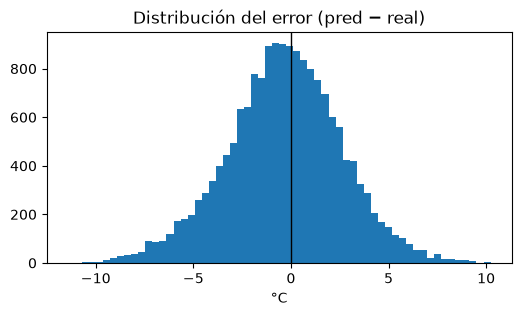

In [20]:
plt.figure(figsize=(6, 3))
plt.hist(err, bins=60)
plt.axvline(0, color="k", lw=1)
plt.title("Distribución del error (pred − real)"); plt.xlabel("°C"); plt.show()

## 13. Conclusiones y siguientes pasos

**Lo que deberías llevarte de este notebook**
1. El **baseline** es el primer modelo, no el último.
2. En series temporales el split es **cronológico**, y la normalización usa solo el **train**.
3. Las **ventanas** (entrada, horizonte, target) son la parte más delicada: verifica siempre la alineación a mano.
4. Densa y CNN ignoran (total o parcialmente) el orden; **LSTM/GRU** lo modelan explícitamente.
5. En PyTorch, vigila las **formas de los tensores**: `Conv1d` quiere `(B, canales, T)`, las RNN con `batch_first=True` quieren `(B, T, F)`.
6. Más capas o parámetros no garantizan mejora: compara siempre en validación.

### 🏋️ Ejercicios (de fácil a difícil)
1. Quita las variables de `Day sin/cos` y `Year sin/cos`. ¿Cuánto empeora cada modelo? ¿Cuál depende más de ellas?
2. Cambia `SEQ_LEN` a 24, 72 y 240. ¿Cuánta historia necesita realmente el modelo?
3. Cambia `HORIZONTE` a 6 y a 72 horas. ¿Cómo evoluciona el error respecto al baseline?
4. Prueba `nn.LSTM(..., bidirectional=True)` (ojo: la salida pasa a tener `2*hidden` y `h_n` tiene 2 estados por capa). Después combina `Conv1d` + `LSTM` (CNN extrae patrones locales → LSTM los lee en orden).
5. Sustituye el `AdaptiveAvgPool1d` de la CNN por `Flatten()` + `Linear`. ¿Mejora? ¿Por qué?
6. Usa en la LSTM `out[:, -1]` en lugar de `h_n[-1]`. ¿Es lo mismo? (Pista: sí, para una LSTM de una capa unidireccional. Compruébalo con `torch.allclose`.)
7. Añade **gradient clipping** (`torch.nn.utils.clip_grad_norm_`) entre `backward()` y `step()` y un **scheduler** de learning rate (`ReduceLROnPlateau`).
8. **Multi-step:** que la red devuelva las próximas 24 horas a la vez (`Linear(hidden, 24)`); tendrás que cambiar `__getitem__` para que `y` sea un vector.

### 🛒 Siguiente proyecto: Kaggle "Store Sales – Time Series Forecasting"
Es el mismo concepto pero más realista y más difícil:
- **Muchas series a la vez** (54 tiendas × 33 familias de producto).
- Variables **exógenas** conocidas de antemano: festivos, promociones, precio del petróleo.
- Se evalúa con **RMSLE** y hay que predecir 16 días por delante.

Lo que has aprendido aquí (Dataset de ventanas, split temporal, baseline, LSTM/CNN) se aplica directamente; se añaden `nn.Embedding` para tienda/familia y un diseño cuidadoso de las ventanas por serie.